# Confronto Euclidean–DCE

Due simulazioni separate, ciascuna con la propria metrica attiva.

Le figure usano lo stesso set_style() della reachability: serif, formule Computer Modern, font 14 pt, curve 1.8 pt, sfondo e legenda bianchi. I dati restano quelli salvati: nessuna interpolazione BRT o simulazione MPC viene rilanciata. Le celle di esportazione salvano in grafici/output e sovrascrivono file omonimi. Nella configurazione puoi disattivare EXPORT o cambiare FORMATS e tempi dei frame.

In [24]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "mpc_utils.py").is_file():
    if (NOTEBOOK_DIR / "grafici/mpc_utils.py").is_file():
        NOTEBOOK_DIR = NOTEBOOK_DIR / "grafici"
    else:
        raise FileNotFoundError("Apri il notebook dalla cartella grafici del repository mpc.")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from plot_utils import set_style
from mpc_utils import (
    repository_root, load_run, run_manifest, compare_scenarios,
    plot_trajectory, plot_trajectories, plot_frames, plot_states, plot_commands,
    plot_values, plot_values_comparison, plot_hj_limits, plot_command_planes,
    plot_costs, cost_consistency, timing_statistics, plot_timings, export_collection,
)

set_style()
ROOT = repository_root(NOTEBOOK_DIR)
EXPORT = True
FORMATS = ("pdf",)  # Anche ("pdf", "eps"). EPS non conserva tutte le trasparenze.
CONTROL_FREQUENCY = 50.0
FRAME_TIMES = (5.0, 7.0, 9.0, 11.0)
VIEW_BEHIND = 10.0
VIEW_AHEAD = 25.0
HJ_STAGE = 0
HJ_SOFTENED = False  # False: vincoli originali senza slack.
PLANE_TIMES = None  # None: tre istanti nell'intervallo HJ attivo.
PER_METRIC_FIGURES = False  # True: aggiunge value e limiti per ciascuna metrica.

figures = {}

def show(name, fig):
    figures[name] = fig
    display(fig)
    plt.close(fig)

RUN_NAMES = ["euclidean", "dce"]
OUTPUT_GROUP = "euclidean_dce"


## Caricamento e confronto dei parametri salvati

Sono controllati stato iniziale, parametri human, velocità di riferimento e passo temporale. I pesi del costo non sono memorizzati negli archivi: la loro uguaglianza non può essere verificata da questi file.

In [25]:
runs = [load_run(name, ROOT) for name in RUN_NAMES]
manifest = run_manifest(runs)
scenario_checks = compare_scenarios(runs)
display(manifest)
display(scenario_checks)


,run,metrics,duration_s,dt_s,steps,predictions,costs,recorded_timers
0,euclidean,euclidean,20.0,0.02,1000,True,True,solve_time
1,dce,dce,20.0,0.02,1000,True,True,solve_time


,run,quantity,same_as_reference
0,dce,dt,True
1,dce,v_ref,True
2,dce,v_H,True
3,dce,X_H_initial,True
4,dce,Y_H_initial,True
5,dce,initial_ego_state,True


## Traiettorie sovrapposte

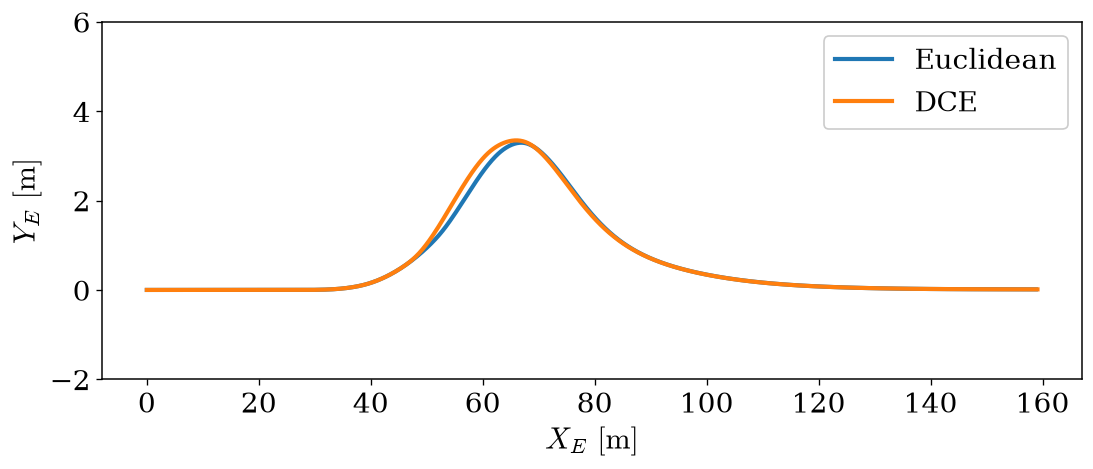

In [26]:
show("euclidean_dce_trajectory", plot_trajectories(runs))


## Frame delle due manovre

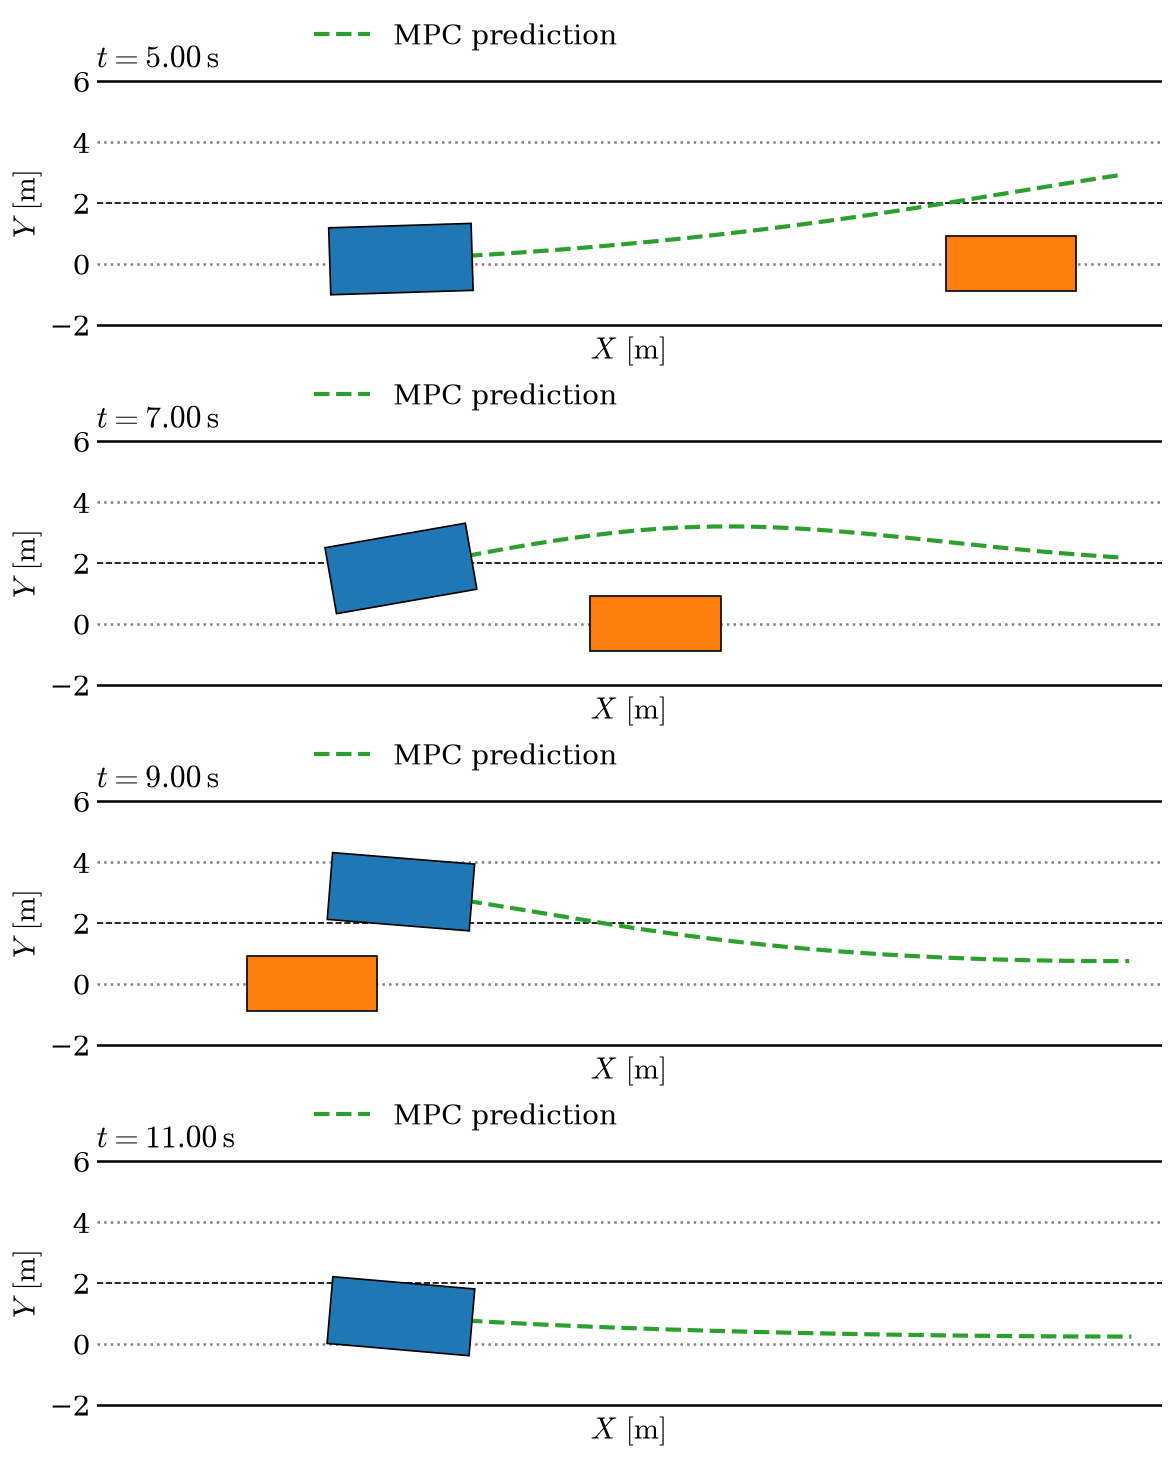

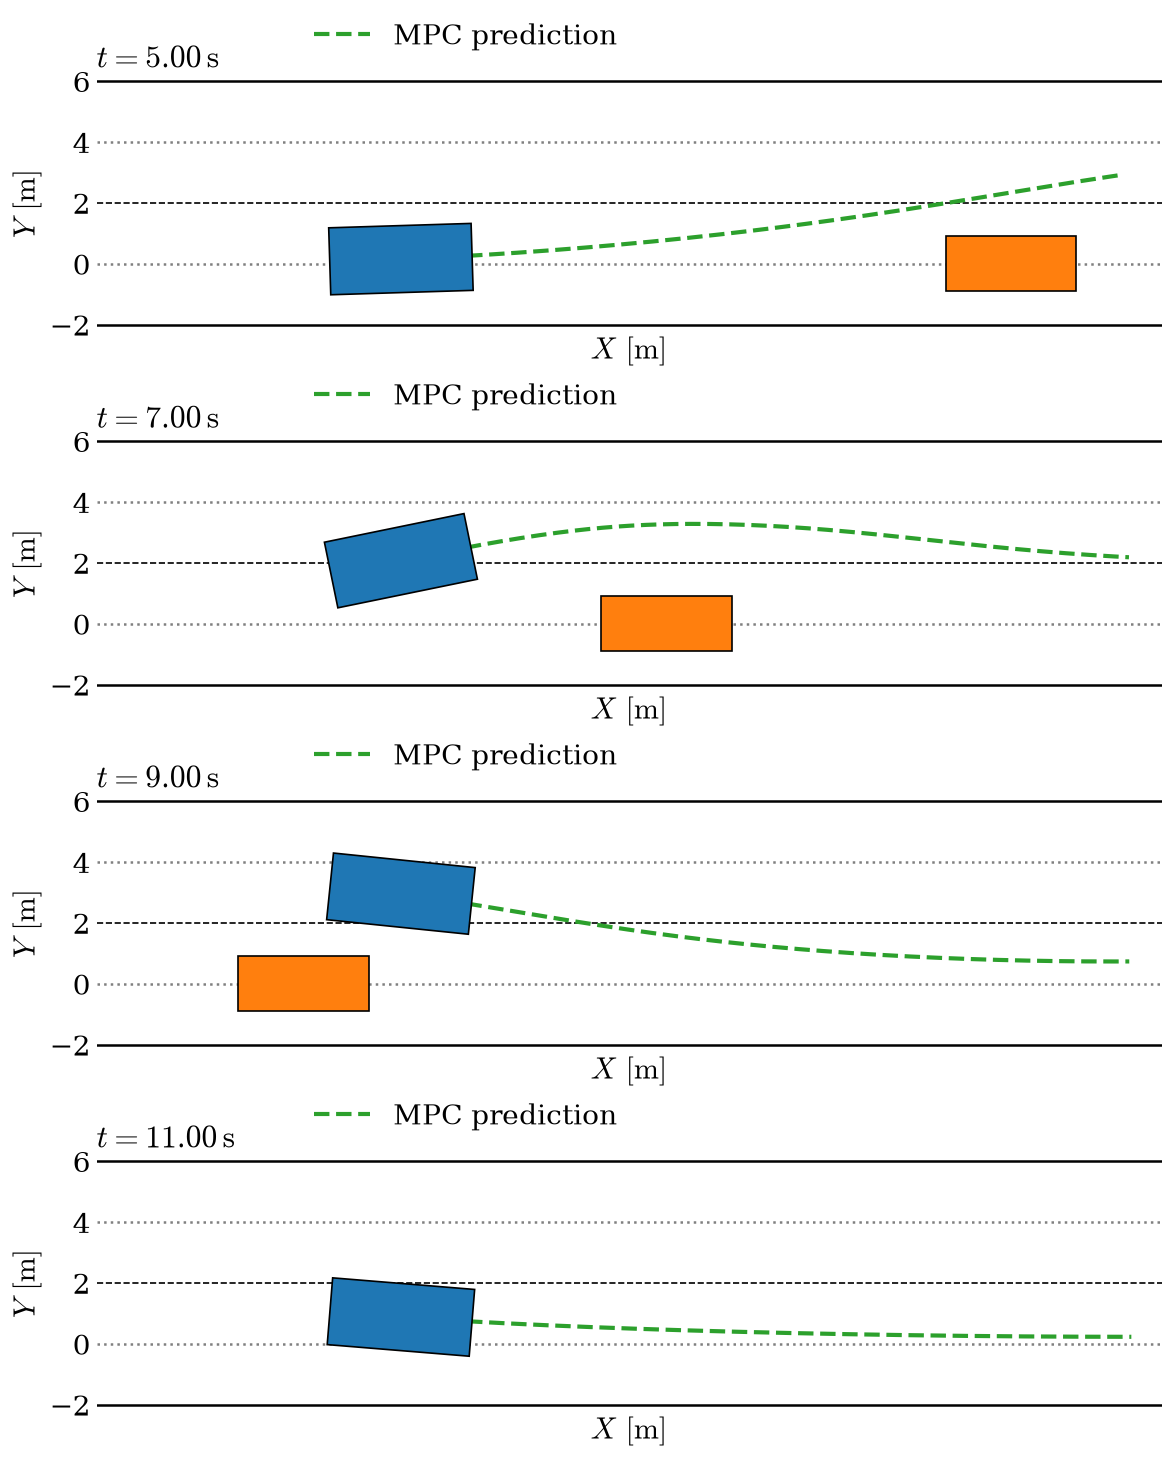

In [27]:
for run in runs:
    show(f"{run.name}_frames", plot_frames(
        run, FRAME_TIMES, behind=VIEW_BEHIND, ahead=VIEW_AHEAD
    ))


## Confronto degli stati

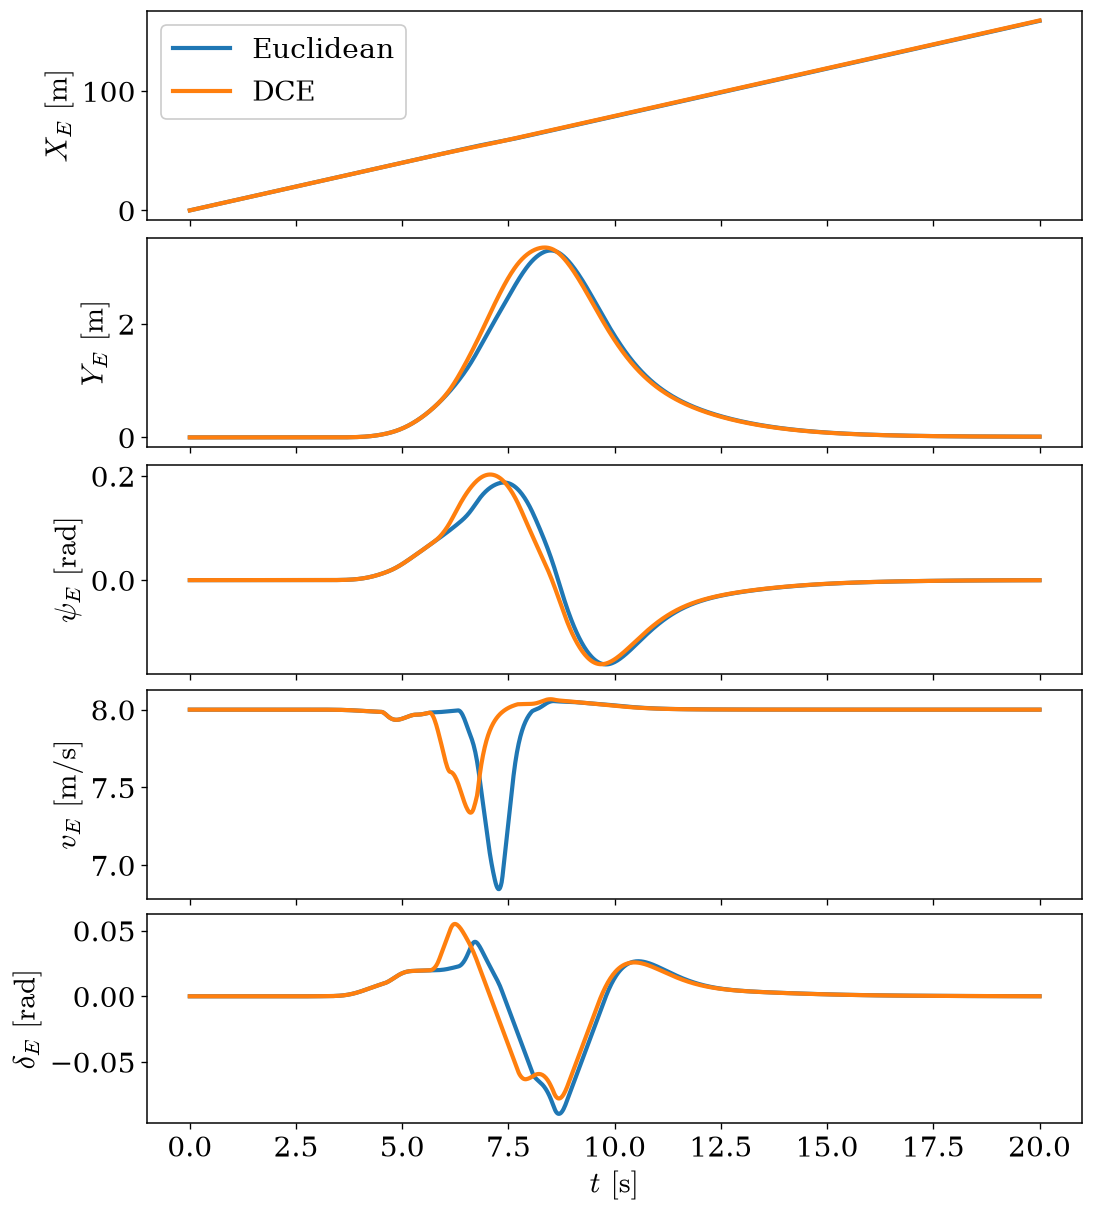

In [28]:
show("euclidean_dce_states", plot_states(runs))


## Confronto dei comandi

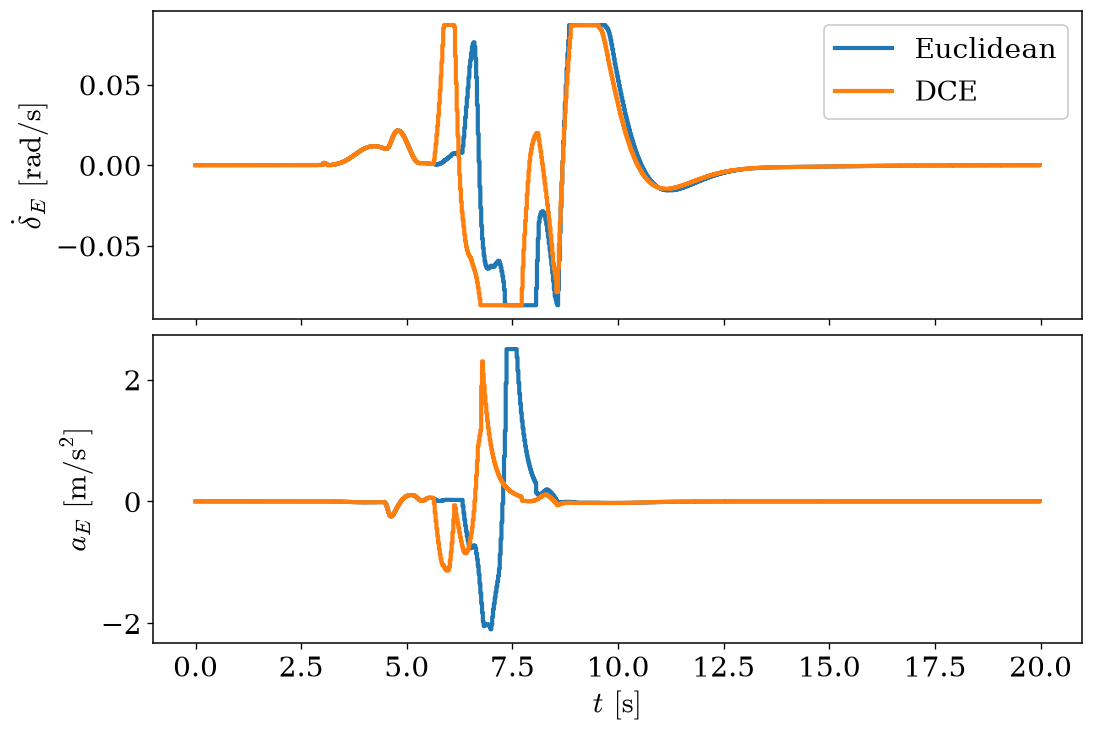

In [29]:
show("euclidean_dce_commands", plot_commands(runs))


## Value function

Pannelli separati, senza normalizzazione arbitraria.

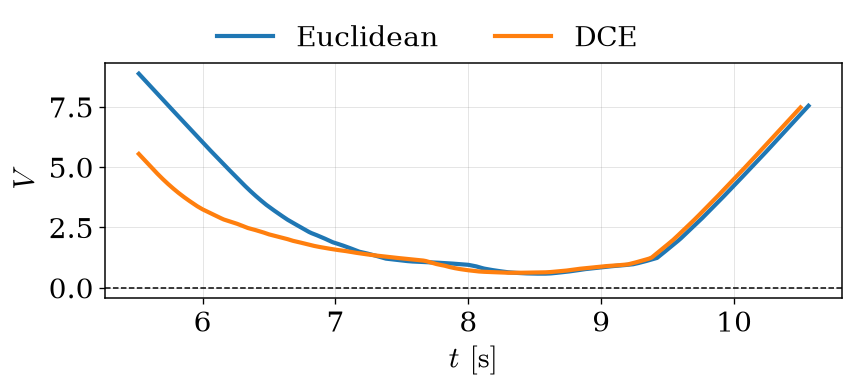

In [30]:
show("euclidean_dce_values", plot_values_comparison(runs))


## Limiti HJ e piano dei comandi

Ogni simulazione conserva i propri vincoli. Gli intervalli sono condizionati al comando complementare registrato; il piano mostra invece la fattibilità congiunta HJ e dei limiti fisici.

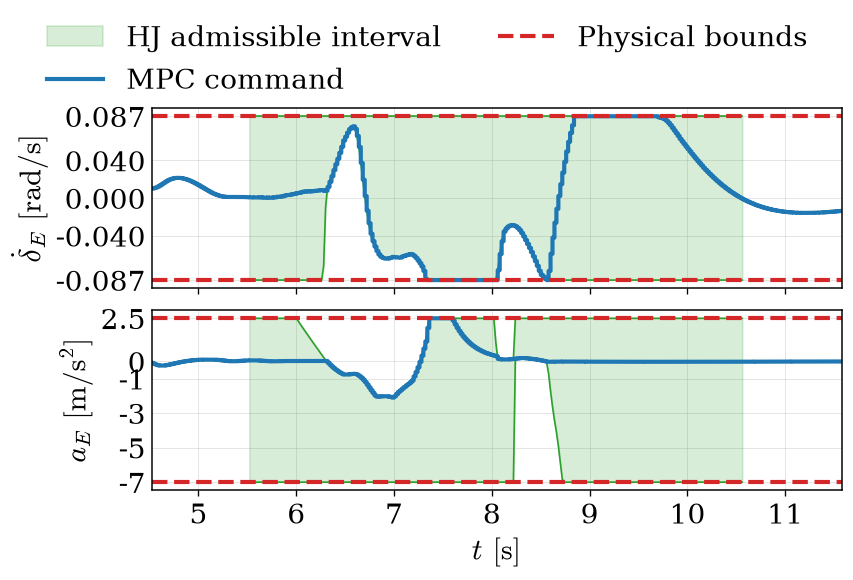

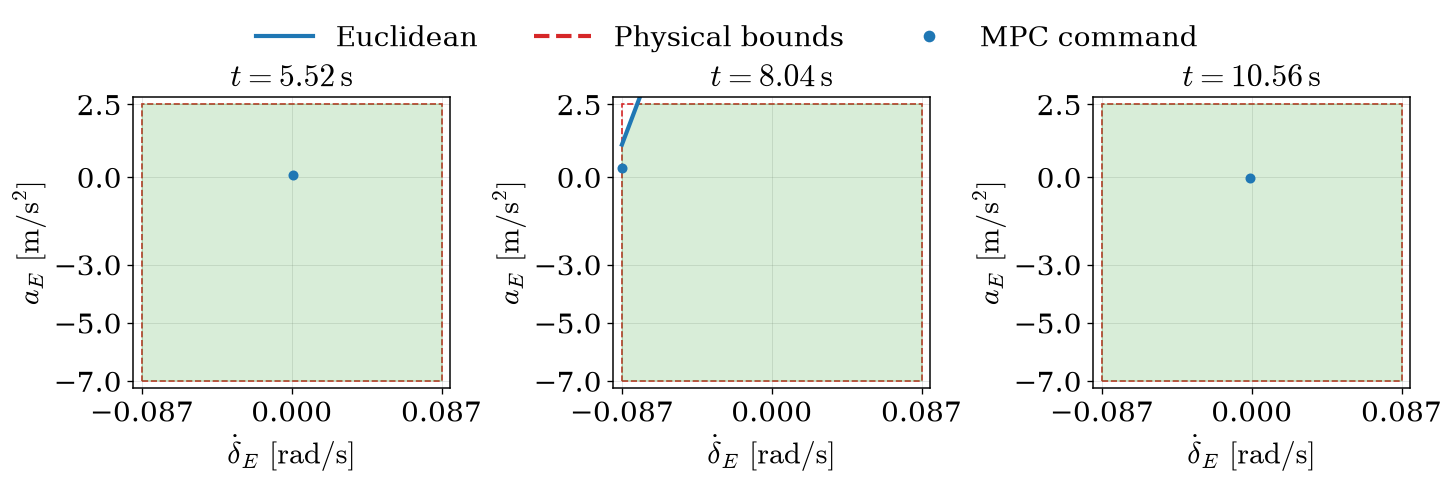

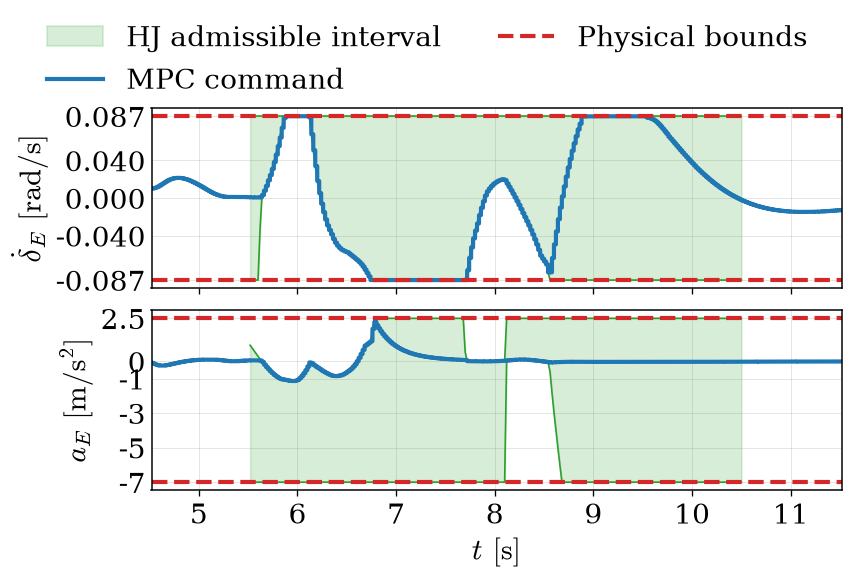

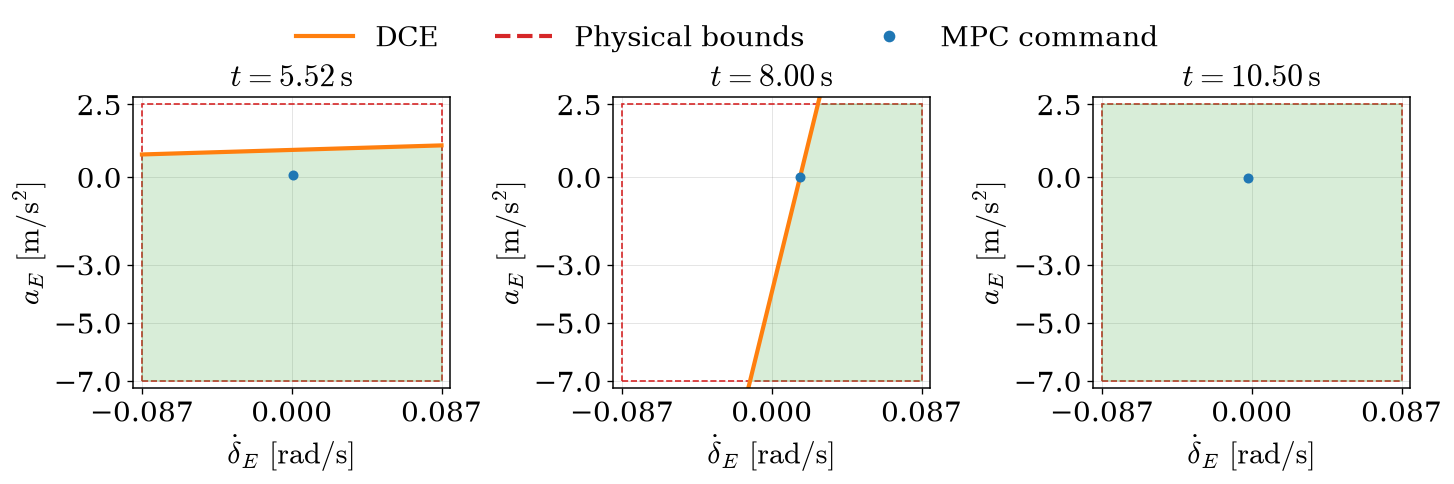

In [31]:
for run in runs:
    fig = plot_hj_limits(
        run, stage=HJ_STAGE, softened=HJ_SOFTENED
    )
    fig.set_size_inches(7, 4.8)
    show(f"{run.name}_hj_limits", fig)

    show(f"{run.name}_command_planes", plot_command_planes(
        run, PLANE_TIMES, stage=HJ_STAGE, softened=HJ_SOFTENED
    ))


## Costi per simulazione

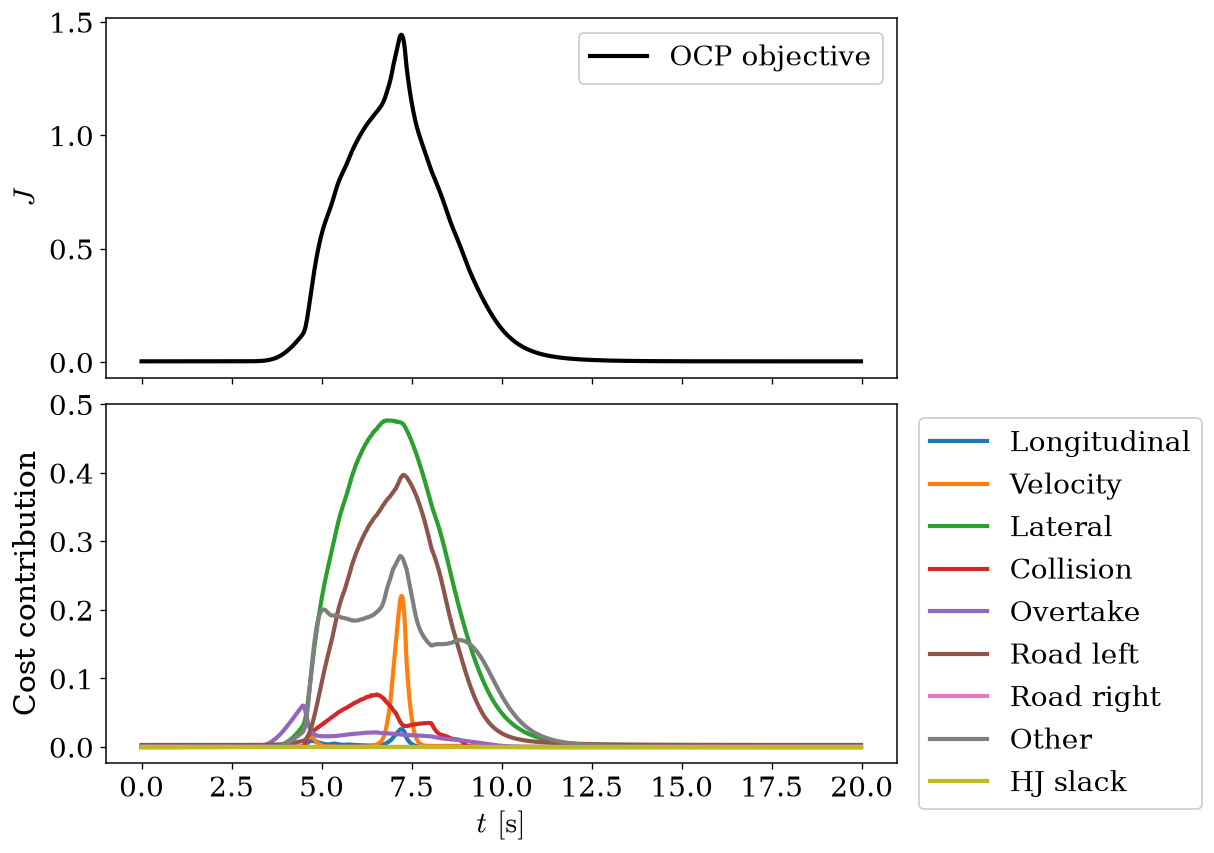

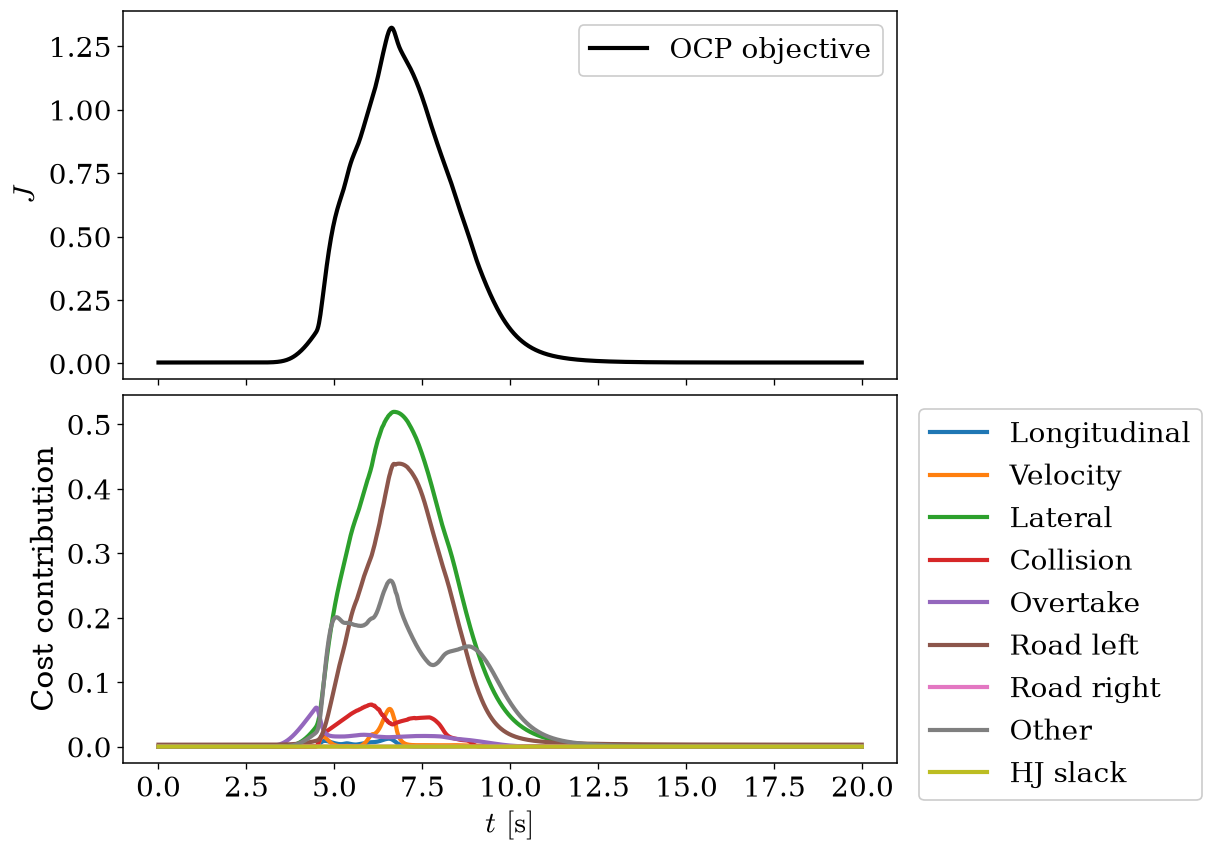

,run,max_abs_decomposition_error
0,euclidean,2.471081e-07
1,dce,1.816157e-07


In [32]:
for run in runs:
    show(f"{run.name}_costs", plot_costs(run))
cost_checks = pd.DataFrame([cost_consistency(run) for run in runs])
display(cost_checks)


## Tempi registrati

Statistiche del solo solver OCP sui dati originali. Nessun costo di interpolazione è ricostruito o stimato. Tutti i campioni sono inclusi.

,run,timer,samples,mean_ms,median_ms,p95_ms,p99_ms,max_ms,deadline_ms,within_deadline_pct,deadline_misses
0,euclidean,OCP solver,1000,103.592,25.485,208.490,442.914,695.822,20.0,49.7,503
1,dce,OCP solver,1000,101.904,54.539,216.821,389.215,427.166,20.0,45.8,542


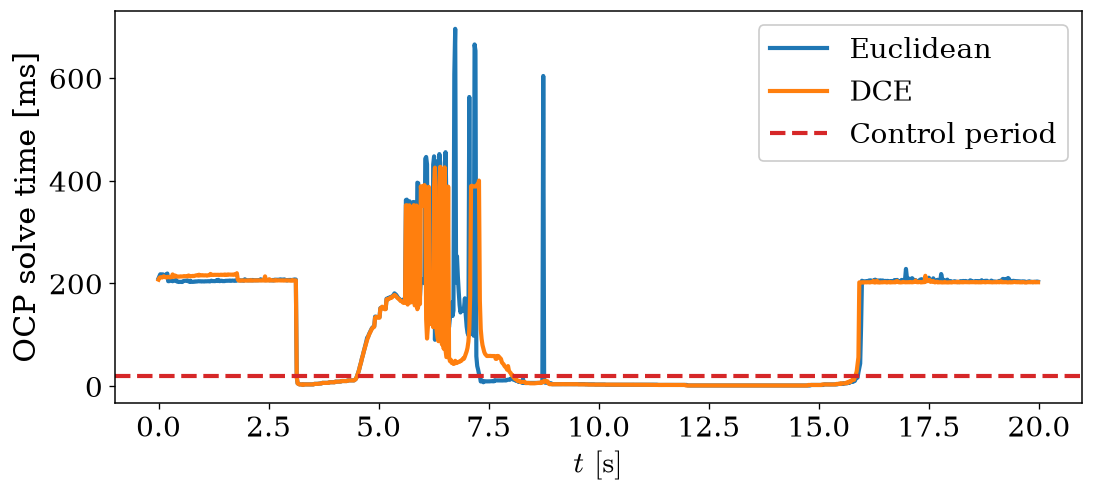

In [33]:
timing_table = timing_statistics(runs, CONTROL_FREQUENCY)
display(timing_table.round(3))
show("euclidean_dce_timings", plot_timings(runs, CONTROL_FREQUENCY))


## Esportazione

In [34]:
if EXPORT:
    exported = export_collection(
        figures, OUTPUT_GROUP, formats=FORMATS,
        tables={"timing_statistics": timing_table, "scenario_checks": scenario_checks,
                "run_manifest": manifest, "cost_consistency": cost_checks},
    )
    print(f"Esportati {len(exported)} file in grafici/output/{OUTPUT_GROUP}")


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/euclidean_dce_trajectory.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/euclidean_frames.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/dce_frames.pdf


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/euclidean_dce_states.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/euclidean_dce_commands.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/euclidean_dce_values.pdf


... (4 outputs left out)

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/euclidean_costs.pdf
Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/dce_costs.pdf


'modified' timestamp seems very low; regarding as unix timestamp


Salvato: /home/alessio-grisorio/TESI/mpc/grafici/output/euclidean_dce/euclidean_dce_timings.pdf
Esportati 17 file in grafici/output/euclidean_dce
